# Do Chatbots Learn to Cooperate? A Prisoner's Dilemma Study
Implementation of the method of **Akata et al. (2025), "Playing repeated games with large language models", Nature Human Behaviour**.

**Method (from the paper):** LLMs play a finitely repeated (10 rounds) 2x2 game with full information. The payoff matrix is turned into plain-text rules, the growing history of past rounds is concatenated into the prompt (in-context learning), temperature = 0, and the choice is the option (J or F) with the highest next-token probability (paper Eq. 3-4). Opponents: other LLMs and simple strategies (Always Defect, Always Cooperate, Defect Once). Then the paper tests (a) prompt-robustness, (b) a "the other player can make mistakes" forgiveness prompt, (c) Social Chain-of-Thought (SCoT): predict the opponent's move first, then choose.

**Runtime:** Runtime > Change runtime type > T4 GPU. Run cells top to bottom.

## 0. Setup

In [1]:
!pip -q install -U transformers accelerate seaborn scipy

In [2]:
import os, json, random, shutil, warnings
from dataclasses import dataclass
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
warnings.filterwarnings("ignore")

import torch
SEED = 42
random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

OUT = "/content/results" if os.path.exists("/content") else "./results"
os.makedirs(OUT, exist_ok=True)

ROUNDS = 10          # paper: 10 rounds
QUICK  = True        # True: 3 prompt variants in the big matrix (fast). False: all 9 (paper-style grid)

# Open, ungated models of increasing size (mirrors the paper's "bigger LLMs do better" comparison).
# Total fp16 memory ~ 10 GB -> fits a free T4 (15 GB). Remove the 3B if you hit out-of-memory.
MODEL_IDS = {
    "Qwen-0.5B": "Qwen/Qwen2.5-0.5B-Instruct",
    "Qwen-1.5B": "Qwen/Qwen2.5-1.5B-Instruct",
    "Qwen-3B":   "Qwen/Qwen2.5-3B-Instruct",
}



## 1. Game, prompt builder (paper Fig. 1 / Eq. 1) and prompt variants

In [3]:
# Action 0 = cooperate (PD)  /  Football (BoS);  action 1 = defect (PD)  /  Ballet (BoS)
@dataclass(frozen=True)
class Game:
    name: str
    payoff: tuple   # payoff[a1][a2] = (points player 1, points player 2)
    def pay(self, player, own, opp):
        # returns (my points, other player's points) from `player`'s perspective
        return self.payoff[own][opp] if player == 1 else self.payoff[opp][own][::-1]

# Paper Eq. (1): (C,C)=(8,8) (C,D)=(0,10) (D,C)=(10,0) (D,D)=(5,5)
PD  = Game("Prisoners_Dilemma", (((8, 8), (0, 10)), ((10, 0), (5, 5))))
# Paper Eq. (2): Battle of the Sexes (optional bonus experiment)
BOS = Game("Battle_of_the_Sexes", (((10, 7), (0, 0)), ((0, 0), (7, 10))))

@dataclass(frozen=True)
class PromptCfg:
    unit: str = "points"             # points / dollars / coins          (paper Fig. 4)
    labels: tuple = ("J", "F")       # label of action 0, action 1        (paper Fig. 4: J/F, X/Q, R/H)
    swap: bool = False               # present the options in swapped order (position-bias check)
    note: str = ""                   # optional extra sentence (forgiveness manipulation)
    @property
    def name(self):
        return f"{self.unit}|{self.labels[0]}/{self.labels[1]}|{'swap' if self.swap else 'std'}|{'note' if self.note else 'plain'}"

# My wording of the paper's manipulation "point out that the other player can make mistakes"
# (exact wording is in the authors' repo/Supplement: github.com/eliaka/repeatedgames)
FORGIVE_NOTE = ("Note that the other player sometimes makes mistakes, i.e. they may "
                "accidentally choose an option that they did not intend to choose.")

def _order(cfg): return [1, 0] if cfg.swap else [0, 1]

def rules_text(game, player, cfg):
    L, o = cfg.labels, _order(cfg)
    lines = []
    for a in o:
        for b in o:
            me, ot = game.pay(player, a, b)
            lines.append(f"If you choose Option {L[a]} and the other player chooses Option {L[b]}, "
                         f"then you win {me} {cfg.unit} and the other player wins {ot} {cfg.unit}.")
    return "\n".join(lines)

def history_text(game, player, hist, cfg):
    L, out = cfg.labels, []
    for i, (own, opp) in enumerate(hist, 1):
        me, ot = game.pay(player, own, opp)
        out.append(f"In round {i}, you chose Option {L[own]} and the other player chose Option {L[opp]}. "
                   f"Thus, you won {me} {cfg.unit} and the other player won {ot} {cfg.unit}.")
    return "\n".join(out)

def context_text(game, player, hist, cfg, rounds=ROUNDS):
    L, o = cfg.labels, _order(cfg)
    s = (f"You are playing a game repeatedly with another player. In this game, you can choose between "
         f"Option {L[o[0]]} and Option {L[o[1]]}. You will play {rounds} rounds in total with the same player. "
         f"The rules of the game are as follows:\n{rules_text(game, player, cfg)}\n")
    if cfg.note: s += cfg.note + "\n"
    if hist:     s += history_text(game, player, hist, cfg) + "\n"
    s += f"You are currently playing round {len(hist) + 1}."
    return s

def question(cfg, kind="act"):
    L, o = cfg.labels, _order(cfg)
    if kind == "act":
        return f"Q: Which Option do you choose, Option {L[o[0]]} or Option {L[o[1]]}?"
    return f"Q: Which Option do you predict the other player will choose, Option {L[o[0]]} or Option {L[o[1]]}?"

UNITS  = ["points", "dollars", "coins"]
LABELS = [("J", "F"), ("X", "Q"), ("R", "H")]
def grid(note="", swap=False, full=None):
    full = (not QUICK) if full is None else full
    cfgs = [PromptCfg(u, l, swap, note) for u in UNITS for l in LABELS]   # 9 variants like paper Fig. 4
    return cfgs if full else [cfgs[0], cfgs[4], cfgs[8]]

BASE_CFG = PromptCfg()

## 2. Agents and the repeated-game engine

In [4]:
class LM:
    # Wraps a HuggingFace chat model. Choice = argmax of next-token probability over the two option labels
    # (paper Eq. 4), temperature 0, no sampling. Results are cached (identical prompt => identical answer).
    def __init__(self, hf_id):
        import torch
        from transformers import AutoTokenizer, AutoModelForCausalLM
        self.torch = torch
        self.tok = AutoTokenizer.from_pretrained(hf_id)
        self.model = AutoModelForCausalLM.from_pretrained(hf_id, torch_dtype=torch.float16, device_map="cuda").eval()
        self.cache = {}
    def check_tokens(self, labels_list):
        for L in labels_list:
            for l in L:
                ids = self.tok.encode(" " + l, add_special_tokens=False)
                if len(ids) != 1: print("WARNING: label", repr(l), "is not a single token:", ids)
    def choose(self, messages, labels, prefix="Option"):
        key = (json.dumps(messages), tuple(labels), prefix)
        if key in self.cache: return self.cache[key]
        torch = self.torch
        text = self.tok.apply_chat_template(messages, tokenize=False, add_generation_prompt=True) + prefix
        enc = self.tok(text, return_tensors="pt", add_special_tokens=False).to(self.model.device)
        with torch.no_grad():
            logits = self.model(**enc).logits[0, -1].float()
        ids = [self.tok.encode(" " + l, add_special_tokens=False)[0] for l in labels]
        lp = torch.log_softmax(logits, -1)[ids]
        k = int(lp.argmax())
        self.cache[key] = (k, float(torch.softmax(lp, -1)[k]))
        return self.cache[key]

class LLMAgent:
    def __init__(self, name, lm, scot=False):
        self.name, self.lm, self.scot = name, lm, scot
    def act(self, player, game, hist, cfg):
        ctx = context_text(game, player, hist, cfg)
        L = cfg.labels
        if not self.scot:
            a, _ = self.lm.choose([{"role": "user", "content": ctx + "\n" + question(cfg, "act")}], L)
        else:
            # Social Chain-of-Thought: first predict the other player's move, then choose given that prediction
            m1 = [{"role": "user", "content": ctx + "\n" + question(cfg, "predict")}]
            pred, _ = self.lm.choose(m1, L)
            m2 = m1 + [{"role": "assistant", "content": f"Option {L[pred]}"},
                       {"role": "user", "content": question(cfg, "act")}]
            a, _ = self.lm.choose(m2, L)
        return a

class Scripted:
    def __init__(self, name, fn): self.name, self.fn = name, fn
    def act(self, player, game, hist, cfg): return self.fn(player, hist)

DEFECT      = Scripted("Defect",      lambda p, h: 1)
COOPERATE   = Scripted("Cooperate",   lambda p, h: 0)
DEFECT_ONCE = Scripted("Defect Once", lambda p, h: 1 if len(h) == 0 else 0)   # paper's "false defector"
TIT_FOR_TAT = Scripted("Tit-for-Tat", lambda p, h: 0 if not h else h[-1][1])  # my extra baseline
FOOTBALL    = Scripted("Football",    lambda p, h: 0)
BALLET      = Scripted("Ballet",      lambda p, h: 1)
def _alt(p, h):
    start = 0 if p == 2 else 1       # start with the option the OTHER player prefers (paper: "for courtesy")
    return start if len(h) % 2 == 0 else 1 - start
ALTERNATE   = Scripted("Alternate", _alt)

def play(a1, a2, game=PD, cfg=BASE_CFG, rounds=ROUNDS):
    h1, h2, s1, s2 = [], [], 0, 0          # h = list of (own action, opponent action)
    for _ in range(rounds):
        x1 = a1.act(1, game, h1, cfg); x2 = a2.act(2, game, h2, cfg)   # simultaneous moves
        h1.append((x1, x2)); h2.append((x2, x1))
        u1, u2 = game.payoff[x1][x2]; s1 += u1; s2 += u2
    return dict(p1=a1.name, p2=a2.name, kind1=type(a1).__name__, acts1=[h[0] for h in h1],
                acts2=[h[0] for h in h2], score1=s1, score2=s2, variant=cfg.name)

def post_betrayal_coop(r):
    # fraction of rounds 2..10 in which BOTH players cooperated (vs "Defect Once" = how forgiving player 1 is)
    return float(np.mean([(x == 0 and y == 0) for x, y in zip(r["acts1"][1:], r["acts2"][1:])]))

def run_matrix(agents, game, cfg):
    rows, o0 = [], (1 if cfg.swap else 0)
    for a1 in agents:
        for a2 in agents:
            r = play(a1, a2, game, cfg)
            r["defect_rate"]     = 100 * float(np.mean(r["acts1"]))                       # % rounds player 1 defected
            r["norm_score"]      = r["score1"] / 100                                      # max possible = 10 rounds x 10
            r["first_listed"]    = float(np.mean([x == o0 for x in r["acts1"]]))          # position-bias diagnostic
            r["joint_coop_post"] = post_betrayal_coop(r)
            rows.append(r)
    return rows

## 3. Load the language models

In [5]:
lms = {n: LM(i) for n, i in MODEL_IDS.items()}
for lm in lms.values(): lm.check_tokens(LABELS)
llm_agents  = [LLMAgent(n, lm) for n, lm in lms.items()]
scot_agents = [LLMAgent(n + " +SCoT", lm, scot=True) for n, lm in lms.items()]
scripted    = [DEFECT, COOPERATE, DEFECT_ONCE]
print("loaded:", [a.name for a in llm_agents])

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


... (20 outputs left out)

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

loaded: ['Qwen-0.5B', 'Qwen-1.5B', 'Qwen-3B']


### Sanity check: look at the exact prompt the model sees, and play one game

In [6]:
demo_hist = [(0, 1), (0, 0)]
print(context_text(PD, 1, demo_hist, BASE_CFG) + "\n" + question(BASE_CFG, "act") + "\nA: Option")
print("-" * 70)
r = play(llm_agents[-1], DEFECT_ONCE, PD, BASE_CFG)
print(r["p1"], "vs", r["p2"], "| LLM actions (0=coop,1=defect):", r["acts1"], "| score:", r["score1"])

You are playing a game repeatedly with another player. In this game, you can choose between Option J and Option F. You will play 10 rounds in total with the same player. The rules of the game are as follows:
If you choose Option J and the other player chooses Option J, then you win 8 points and the other player wins 8 points.
If you choose Option J and the other player chooses Option F, then you win 0 points and the other player wins 10 points.
If you choose Option F and the other player chooses Option J, then you win 10 points and the other player wins 0 points.
If you choose Option F and the other player chooses Option F, then you win 5 points and the other player wins 5 points.
In round 1, you chose Option J and the other player chose Option F. Thus, you won 0 points and the other player won 10 points.
In round 2, you chose Option J and the other player chose Option J. Thus, you won 8 points and the other player won 8 points.
You are currently playing round 3.
Q: Which Option do you

## 4. Experiment 1 - all pairings (paper Fig. 3a)

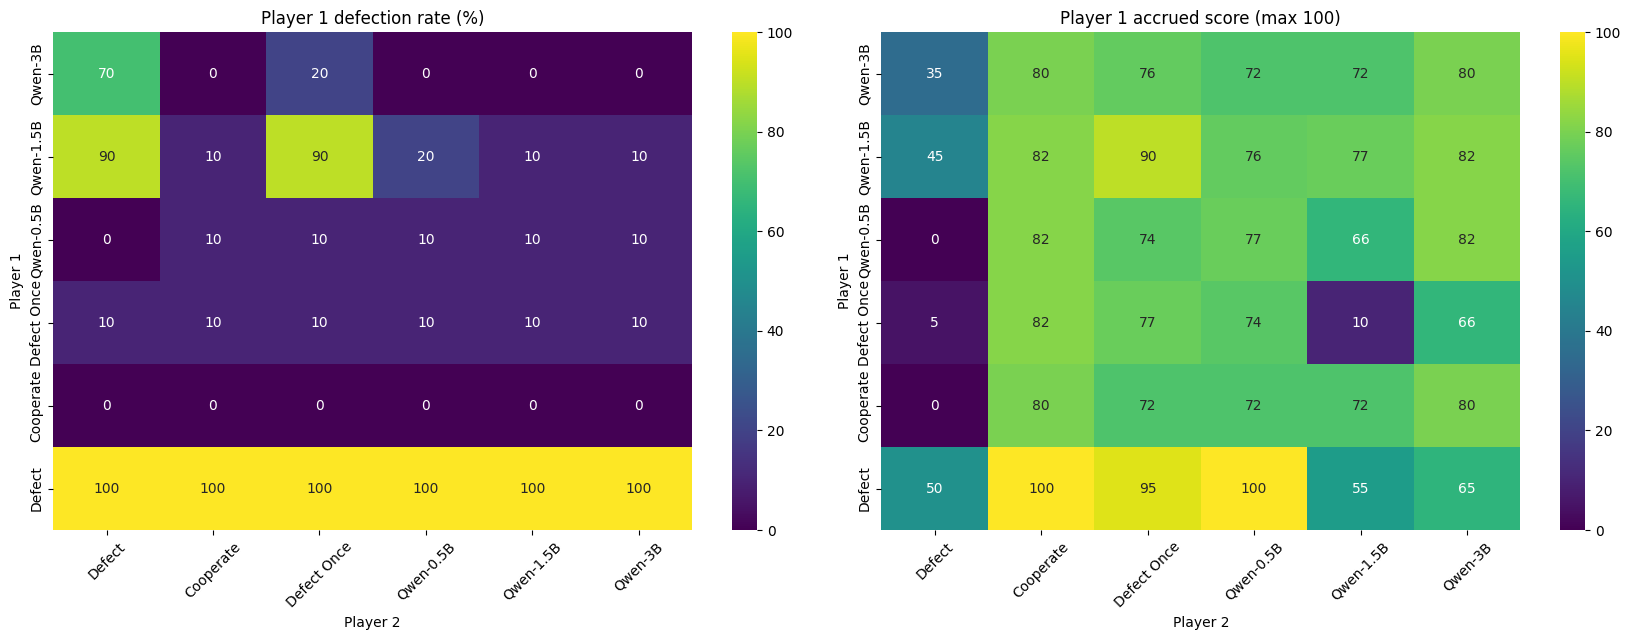

In [7]:
def plot_heatmaps(df, order, fname):
    fig, ax = plt.subplots(1, 2, figsize=(17, 6.5))
    for a, col, title in zip(ax, ["defect_rate", "score1"],
                             ["Player 1 defection rate (%)", "Player 1 accrued score (max 100)"]):
        pv = df.pivot_table(index="p1", columns="p2", values=col).reindex(index=order[::-1], columns=order)
        sns.heatmap(pv, annot=True, fmt=".0f", cmap="viridis", vmin=0, vmax=100, ax=a)
        a.set_title(title); a.set_xlabel("Player 2"); a.set_ylabel("Player 1")
        a.tick_params(axis="x", rotation=45)
    plt.tight_layout(); plt.savefig(f"{OUT}/{fname}", dpi=200); plt.show()

agents_main = scripted + llm_agents
rows1 = run_matrix(agents_main, PD, BASE_CFG)
df1 = pd.DataFrame(rows1)
df1.drop(columns=["acts1", "acts2"]).to_csv(f"{OUT}/exp1_matrix_base_prompt.csv", index=False)
plot_heatmaps(df1, [a.name for a in agents_main], "fig_exp1_heatmaps.png")

### Round-by-round behaviour (paper Fig. 3b): who forgives the 'Defect Once' player?

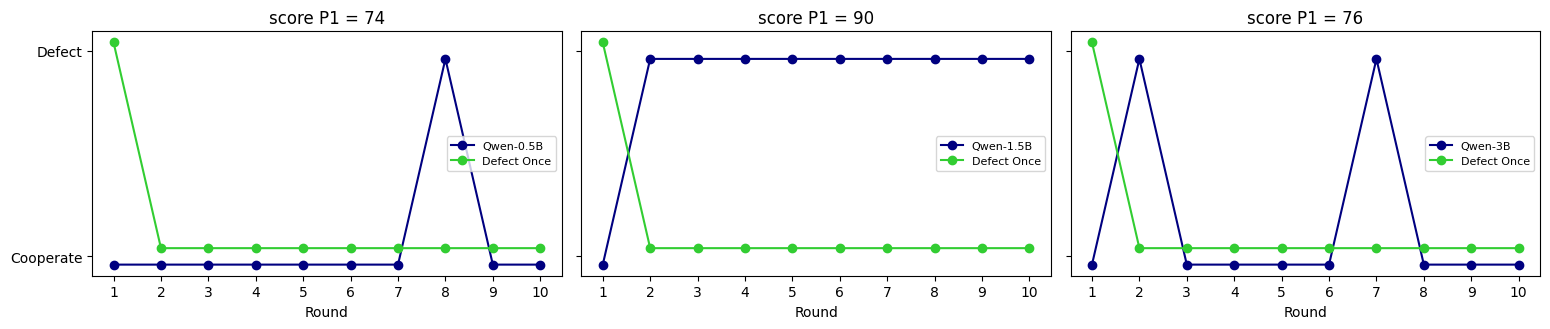

In [8]:
def plot_traj(results, fname):
    fig, axs = plt.subplots(1, len(results), figsize=(5.2 * len(results), 3.4), sharey=True)
    axs = np.atleast_1d(axs)
    for ax, r in zip(axs, results):
        x = np.arange(1, len(r["acts1"]) + 1)
        ax.plot(x, np.array(r["acts1"]) - 0.04, "o-", label=r["p1"], color="navy")
        ax.plot(x, np.array(r["acts2"]) + 0.04, "o-", label=r["p2"], color="limegreen")
        ax.set_yticks([0, 1]); ax.set_yticklabels(["Cooperate", "Defect"]); ax.set_xticks(x)
        ax.set_xlabel("Round"); ax.legend(loc="center right", fontsize=8); ax.set_title(f"score P1 = {r['score1']}")
    plt.tight_layout(); plt.savefig(f"{OUT}/{fname}", dpi=200); plt.show()

plot_traj([play(a, DEFECT_ONCE, PD, BASE_CFG) for a in llm_agents], "fig_exp1_trajectories.png")

## 5. Experiment 2 - prompt robustness (paper Fig. 4, left)
Does the (un)forgiving behaviour depend on units (points/dollars/coins) or option labels (J/F, X/Q, R/H)?

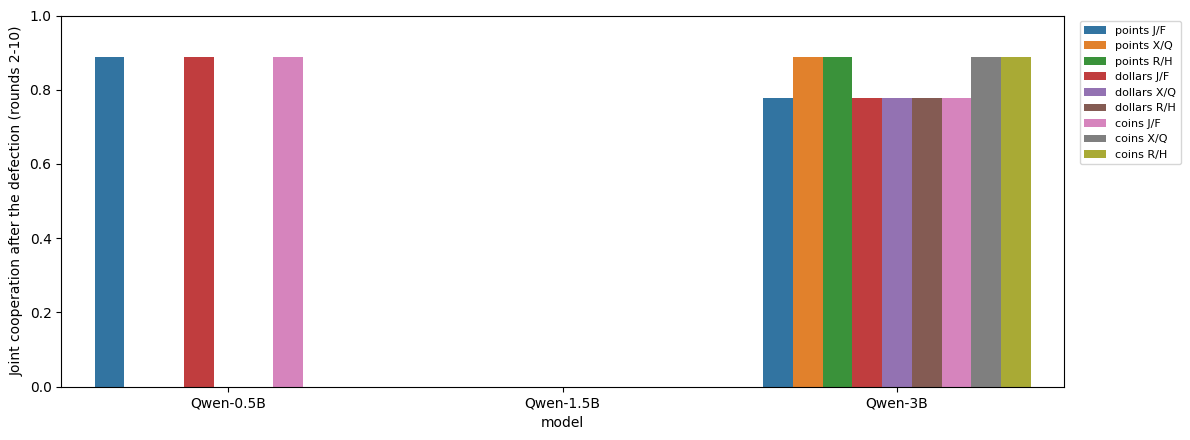

In [9]:
rows = []
for ag in llm_agents:
    for cfg in grid(full=True):
        r = play(ag, DEFECT_ONCE, PD, cfg)
        rows.append(dict(model=ag.name, variant=f"{cfg.unit} {cfg.labels[0]}/{cfg.labels[1]}", joint_coop=post_betrayal_coop(r)))
d_rob = pd.DataFrame(rows); d_rob.to_csv(f"{OUT}/exp2_robustness.csv", index=False)
plt.figure(figsize=(12, 4.5))
sns.barplot(data=d_rob, x="model", y="joint_coop", hue="variant")
plt.ylabel("Joint cooperation after the defection (rounds 2-10)"); plt.ylim(0, 1)
plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8); plt.tight_layout()
plt.savefig(f"{OUT}/fig_exp2_robustness.png", dpi=200); plt.show()

## 6. Experiment 3 - can we make chatbots cooperate? (forgiveness prompt and SCoT)
Opponent: *Defect Once*. Metric: joint cooperation in rounds 2-10 (1.0 = fully forgave and re-established cooperation).

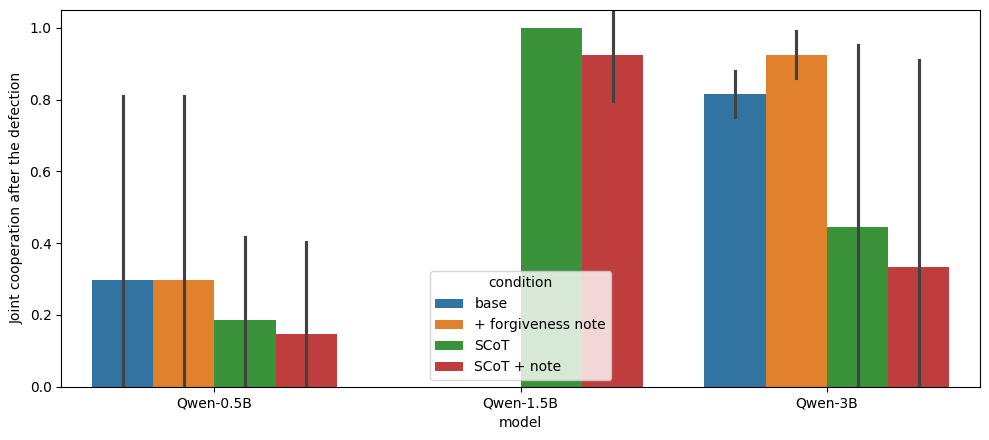

                              joint_coop  score
model     condition                            
Qwen-0.5B + forgiveness note        0.30  88.00
          SCoT                      0.19  88.33
          SCoT + note               0.15  87.33
          base                      0.30  88.00
Qwen-1.5B + forgiveness note        0.00  91.67
          SCoT                      1.00  72.00
          SCoT + note               0.93  73.33
          base                      0.00  91.67
Qwen-3B   + forgiveness note        0.93  76.67
          SCoT                      0.44  83.67
          SCoT + note               0.33  84.00
          base                      0.81  78.67


In [10]:
conds = {"base": (False, ""), "+ forgiveness note": (False, FORGIVE_NOTE),
         "SCoT": (True, ""), "SCoT + note": (True, FORGIVE_NOTE)}
rows = []
for mname, lm in lms.items():
    for cname, (scot, note) in conds.items():
        ag = LLMAgent(mname, lm, scot)
        for cfg in grid(note=note):
            r = play(ag, DEFECT_ONCE, PD, cfg)
            rows.append(dict(model=mname, condition=cname, variant=cfg.name, joint_coop=post_betrayal_coop(r), score=r["score1"]))
d_int = pd.DataFrame(rows); d_int.to_csv(f"{OUT}/exp3_interventions.csv", index=False)
plt.figure(figsize=(10, 4.5))
sns.barplot(data=d_int, x="model", y="joint_coop", hue="condition", errorbar="sd")
plt.ylabel("Joint cooperation after the defection"); plt.ylim(0, 1.05); plt.tight_layout()
plt.savefig(f"{OUT}/fig_exp3_interventions.png", dpi=200); plt.show()
print(d_int.groupby(["model", "condition"])[["joint_coop", "score"]].mean().round(2))

## 7. Experiment 4 - full comparison table and statistics (paper Table 1 style, PD only)
Runs the full matrix (incl. SCoT agents) over several prompt variants, then compares models with Welch t-tests and Cohen's d.

,norm_score,defect_rate,forgiveness_vs_DefectOnce,position_bias
p1,,,,
Defect,0.715,100.000,0.000,NaN
Cooperate,0.453,0.000,1.000,NaN
Defect Once,0.455,10.000,1.000,NaN
Qwen-0.5B,0.654,69.630,0.296,0.304
Qwen-1.5B,0.677,65.556,0.000,0.344
Qwen-3B,0.630,56.667,0.815,0.433
Qwen-0.5B +SCoT,0.669,73.333,0.185,0.267
Qwen-1.5B +SCoT,0.468,11.481,1.000,0.885
Qwen-3B +SCoT,0.649,57.037,0.444,0.430



Welch t-tests on normalised score (score/100); reference = Qwen-3B
Qwen-3B vs Qwen-0.5B         t =  -0.41  p = 0.6860  d = -0.11
Qwen-3B vs Qwen-1.5B         t =  -0.89  p = 0.3778  d = -0.24
Qwen-3B vs Qwen-3B +SCoT     t =  -0.36  p = 0.7183  d = -0.10
Note: games share opponents/variants, so treat p-values as descriptive, not strict inference.


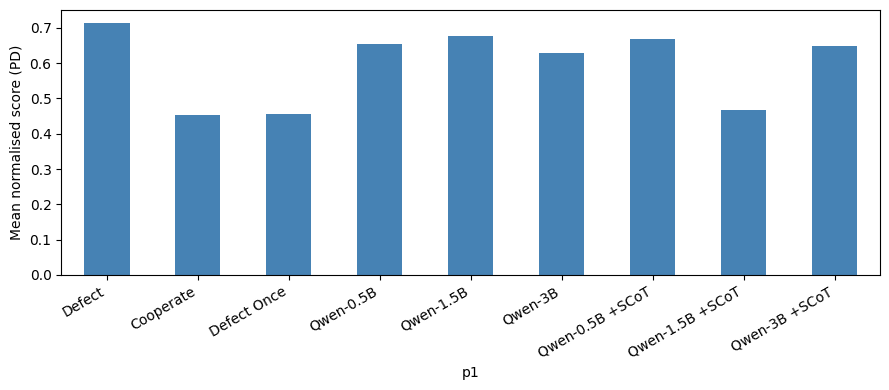

In [11]:
agents_all = scripted + llm_agents + scot_agents
all_rows = []
for cfg in grid():
    all_rows += run_matrix(agents_all, PD, cfg)
df_all = pd.DataFrame(all_rows)
df_all.drop(columns=["acts1", "acts2"]).to_csv(f"{OUT}/exp4_all_games.csv", index=False)

names = [a.name for a in agents_all]
tab = df_all.groupby("p1").agg(norm_score=("norm_score", "mean"), defect_rate=("defect_rate", "mean")).reindex(names)
tab["forgiveness_vs_DefectOnce"] = df_all[df_all.p2 == "Defect Once"].groupby("p1")["joint_coop_post"].mean()
tab["position_bias"] = df_all[df_all.kind1 == "LLMAgent"].groupby("p1")["first_listed"].mean()   # 0.5 = no bias, 1.0 = always first option
tab = tab.round(3); tab.to_csv(f"{OUT}/exp4_summary_table.csv"); display(tab)

def cohen_d(x, y):
    sp = np.sqrt(((len(x) - 1) * x.var(ddof=1) + (len(y) - 1) * y.var(ddof=1)) / (len(x) + len(y) - 2))
    return (x.mean() - y.mean()) / sp if sp > 0 else float("nan")

big = llm_agents[-1].name
print(f"\nWelch t-tests on normalised score (score/100); reference = {big}")
for other in [a.name for a in llm_agents[:-1]] + [scot_agents[-1].name]:
    x = df_all[df_all.p1 == big].norm_score; y = df_all[df_all.p1 == other].norm_score
    t, p = stats.ttest_ind(x, y, equal_var=False)
    print(f"{big} vs {other:16s}  t = {t:6.2f}  p = {p:.4f}  d = {cohen_d(x, y):5.2f}")
print("Note: games share opponents/variants, so treat p-values as descriptive, not strict inference.")

plt.figure(figsize=(9, 4)); tab["norm_score"].plot(kind="bar", color="steelblue")
plt.ylabel("Mean normalised score (PD)"); plt.xticks(rotation=30, ha="right"); plt.tight_layout()
plt.savefig(f"{OUT}/fig_exp4_scores.png", dpi=200); plt.show()

## 8. (Optional bonus) Battle of the Sexes - coordination (paper Fig. 5)
Run only if you have time left; it shows the 'cooperates well but cannot coordinate' contrast the paper reports.

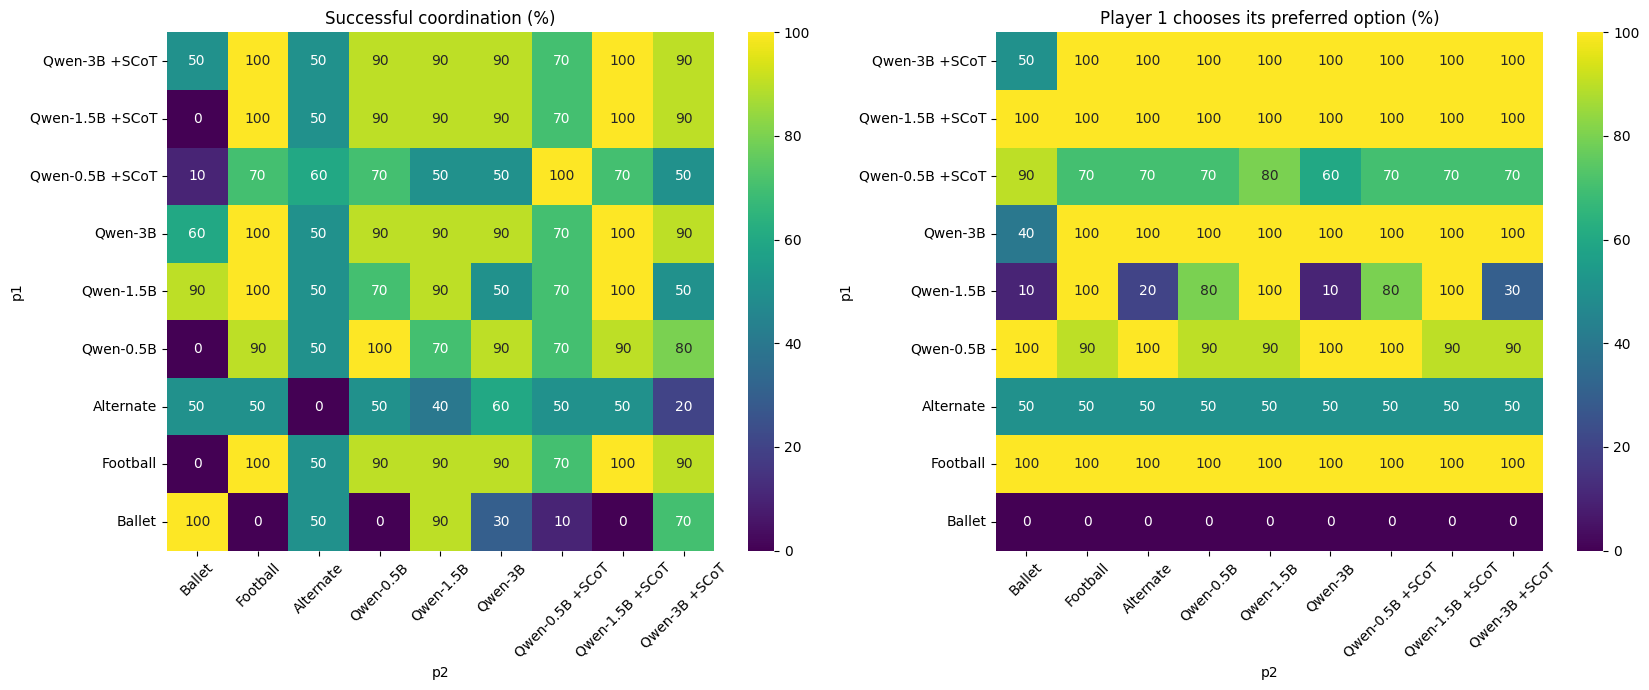

In [12]:
bos_agents = [BALLET, FOOTBALL, ALTERNATE] + llm_agents + scot_agents
rows = []
for a1 in bos_agents:
    for a2 in bos_agents:
        r = play(a1, a2, BOS, BASE_CFG)
        r["coordination"] = 100 * float(np.mean([x == y for x, y in zip(r["acts1"], r["acts2"])]))
        r["pref_option"]  = 100 * float(np.mean([x == 0 for x in r["acts1"]]))   # player 1 prefers football (action 0)
        rows.append(r)
d_bos = pd.DataFrame(rows); order = [a.name for a in bos_agents]
fig, ax = plt.subplots(1, 2, figsize=(17, 7))
for a, col, t in zip(ax, ["coordination", "pref_option"], ["Successful coordination (%)", "Player 1 chooses its preferred option (%)"]):
    pv = d_bos.pivot_table(index="p1", columns="p2", values=col).reindex(index=order[::-1], columns=order)
    sns.heatmap(pv, annot=True, fmt=".0f", cmap="viridis", vmin=0, vmax=100, ax=a); a.set_title(t); a.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.savefig(f"{OUT}/fig_bonus_bos.png", dpi=200); plt.show()

## 9. (Optional) Play against the chatbot yourself
A tiny stand-in for the paper's human study. Ask classmates to play and note their results.

In [13]:
def human_vs(agent, cfg=BASE_CFG, rounds=ROUNDS):
    ag_h, me_h, s_me, s_ai = [], [], 0, 0
    for r in range(rounds):
        a_ai = agent.act(2, PD, ag_h, cfg)
        while True:
            c = input(f"Round {r+1}/{rounds}: [c]ooperate or [d]efect? ").strip().lower()
            if c in ("c", "d"): break
        a_me = 0 if c == "c" else 1
        u_me, u_ai = PD.payoff[a_me][a_ai]; s_me += u_me; s_ai += u_ai
        ag_h.append((a_ai, a_me))
        print(f"   you: {'C' if a_me == 0 else 'D'} | {agent.name}: {'C' if a_ai == 0 else 'D'} | totals you {s_me}, AI {s_ai}")
    return s_me, s_ai

# human_vs(scot_agents[-1])     # uncomment to play

## 10. Save everything for your report

In [14]:
shutil.make_archive("/content/results" if os.path.exists("/content") else "results", "zip", OUT)
try:
    from google.colab import files; files.download("/content/results.zip")
except Exception as e:
    print("Results are in", OUT)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [15]:
!pip freeze | grep -iE "^(torch|transformers|accelerate|seaborn|scipy|numpy|pandas|matplotlib)=="

accelerate==1.16.0
matplotlib==3.10.0
numpy==2.4.6
pandas==2.2.3
scipy==1.18.1
seaborn==0.13.2
torch==2.14.1+cu130
transformers==5.23.0
